# Notebook 21a — Wu 2003: Control Structure Comparison (S-B vs S-C), All Scenarios

## Purpose

Companion to `notebooks/21_wu2003_control_structures.ipynb`, systematically comparing S-B
(no analyzer) against **S-C** (S-B + feed-line composition analyzer) across all 14
closed-loop fault scenarios, using the same 2-hour observation window as SBI training.

**What is and is not new here.** `nb20a` Section 1 already confirmed S-C's raw plant
dynamics are byte-identical to S-B's (no new control loop). So `nb21`'s `F_R_norm` and
`x_D` grids, its S-B steady-state table, and its open-loop-vs-closed-loop masking figure
(all pure S-B/S-A physics) would be exact reproductions if rerun here -- **not repeated**.
This notebook's new content is the feed-analyzer channel itself, systematically checked
across every scenario rather than the 4-scenario preview in `nb20a`.

## Contents

1. Feed-analyzer readings across all 14 closed-loop scenarios (grid, mirrors `nb21`
   Section 3/4's layout)
2. Comparison table: true `z_A0_eff` vs. feed-analyzer reading vs. S-B's `F_R_norm`/`T_reb`
   (does the reactor-linked channel track `z_A0_eff`, or does the feed analyzer?)
3. Which scenario pairs does the analyzer disambiguate, systematically (not just the
   4-scenario `nb20a` preview)

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cstr_sbi.recycle.scenarios import list_closed_loop
from cstr_sbi.recycle.simulator import nominal_warm_start, deterministic_window
from cstr_sbi.recycle.summaries import feed_analyzer_reading, FEED_ANALYZER_NOISE_PCT, Z_A0_EFF_PARAM_IDX
import pathlib
FIGURES = pathlib.Path('../figures'); FIGURES.mkdir(exist_ok=True)
OI = ["#000000","#E69F00","#56B4E9","#009E73","#F0E442","#0072B2","#D55E00","#CC79A7"]

print("Computing S-B warm start (shared with S-C, confirmed identical in nb20a)...")
y0_sb = nominal_warm_start("S-B")
configs = list_closed_loop()
print(f"{len(configs)} closed-loop scenarios")

Computing S-B warm start (shared with S-C, confirmed identical in nb20a)...


14 closed-loop scenarios


## Section 1 — Generate 2h Windows and Feed-Analyzer Readings for All Scenarios

Raw trajectories reused from S-B (identical for S-C per `nb20a` Section 1); feed-analyzer
readings computed per scenario with an independent noise seed each.

In [2]:
raw_sb = {}
feed_readings = {}
t_h = None
rng_master = np.random.default_rng(2026)

for i, sc in enumerate(configs):
    t_s, r_sb = deterministic_window(sc, structure="S-B", y0=y0_sb, t_final_h=2.0, n_save=120)
    r_sb = np.asarray(r_sb)
    theta = np.asarray(sc.theta())
    reading = feed_analyzer_reading(theta, np.asarray(t_s), rng_master)
    raw_sb[sc.name] = r_sb
    feed_readings[sc.name] = reading
    if t_h is None:
        t_h = np.asarray(t_s)
    print(f"  [{i+1:2d}/{len(configs)}] {sc.name}  (z_A0_eff={theta[Z_A0_EFF_PARAM_IDX]:.2f})")

print("Done.")

  [ 1/14] W1_healthy  (z_A0_eff=0.90)
  [ 2/14] W2_cat_mild  (z_A0_eff=0.90)
  [ 3/14] W3_cat_severe  (z_A0_eff=0.90)


  [ 4/14] W4_cat_threshold  (z_A0_eff=0.90)
  [ 5/14] W5_jacket_mild  (z_A0_eff=0.90)
  [ 6/14] W6_jacket_severe  (z_A0_eff=0.90)


  [ 7/14] W7_col_eff_mild  (z_A0_eff=0.90)
  [ 8/14] W9_reb_fouling  (z_A0_eff=0.90)
  [ 9/14] W10_feed_impurity  (z_A0_eff=0.78)


  [10/14] W11_reactor_combined  (z_A0_eff=0.90)


  [11/14] W12_snowball_compound  (z_A0_eff=0.90)
  [12/14] W13_cat_feed  (z_A0_eff=0.80)
  [13/14] W15_snowball_threshold  (z_A0_eff=0.90)


  [14/14] W16_full_multi  (z_A0_eff=0.90)
Done.


## Section 2 — Feed-Analyzer Reading Grid, All Scenarios

Each panel shows the feed-analyzer trace (flat, since `z_A0_eff` doesn't vary within a
scenario) alongside the true `z_A0_eff` value. Unlike `nb21`'s `F_R_norm`/`x_D` grids, this
one should look almost identical in *shape* across scenarios (a flat noisy line) but differ
in *level* -- exactly matching each scenario's own `z_A0_eff`, and nothing else.

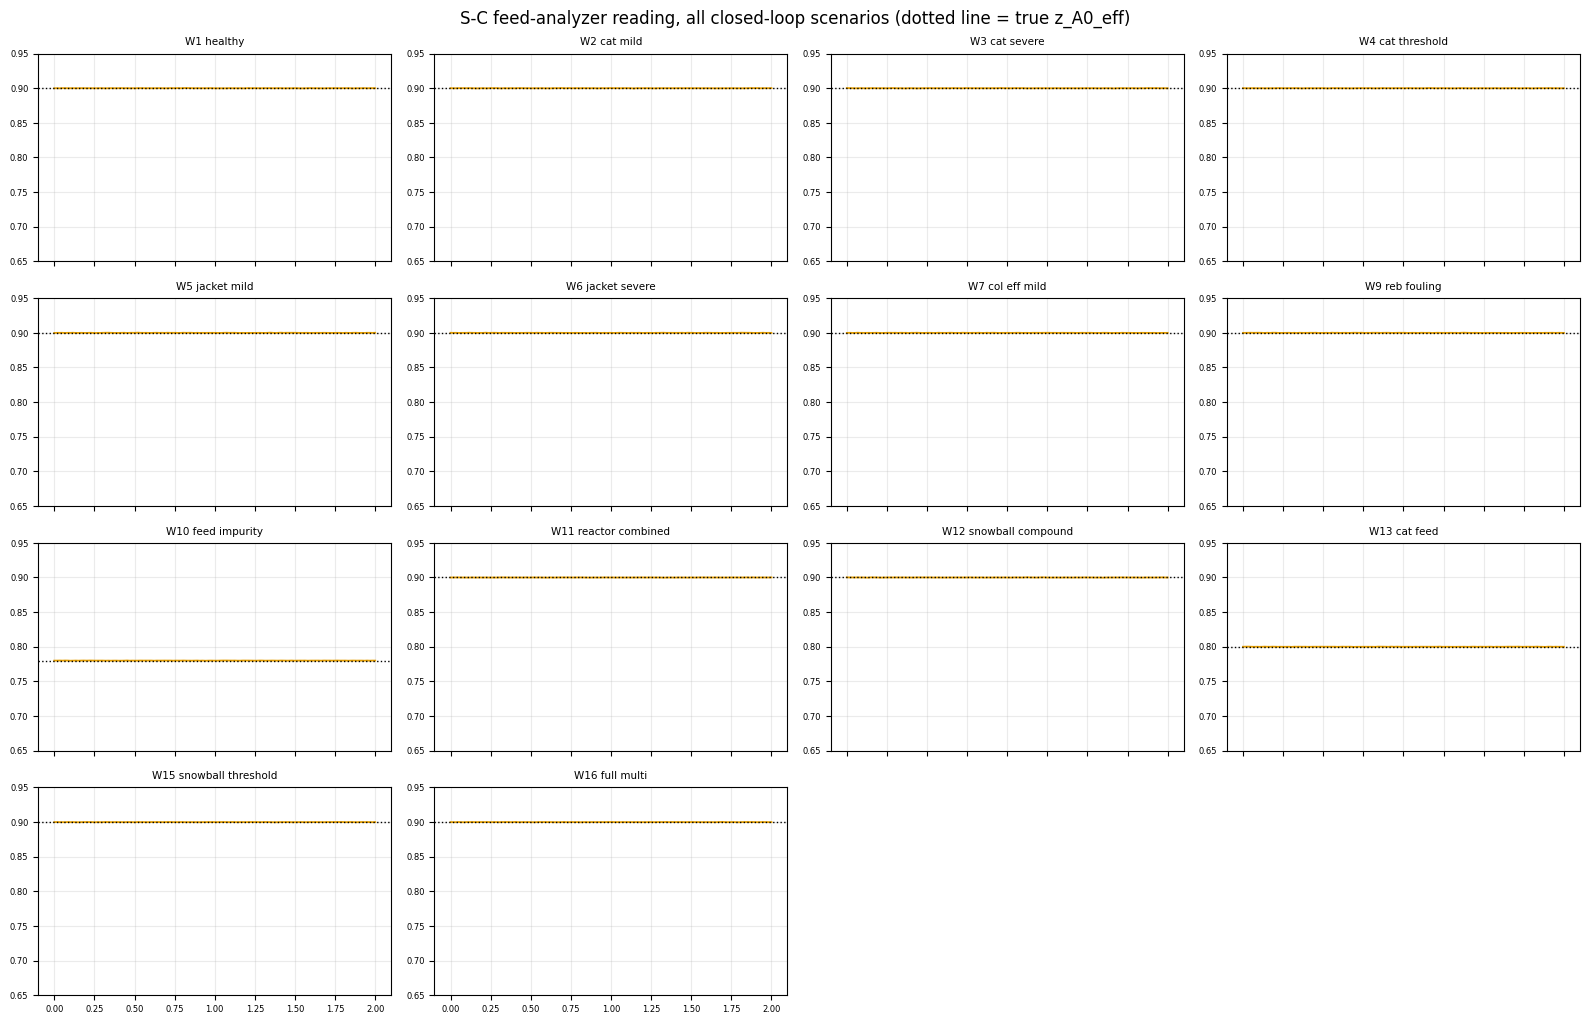

Saved 21a_feed_analyzer_all_scenarios.png


In [3]:
n = len(configs)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows), sharex=True)
axes = axes.flatten()

for i, sc in enumerate(configs):
    ax = axes[i]
    theta = np.asarray(sc.theta())
    ax.plot(t_h, feed_readings[sc.name], color=OI[1], lw=1.3)
    ax.axhline(theta[Z_A0_EFF_PARAM_IDX], color=OI[0], ls=':', lw=1.0)
    ax.set_title(sc.name.replace('_', ' '), fontsize=7.5)
    ax.set_ylim(0.65, 0.95)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=6)
for j in range(n, len(axes)):
    axes[j].axis('off')

fig.suptitle('S-C feed-analyzer reading, all closed-loop scenarios (dotted line = true z_A0_eff)', fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / '21a_feed_analyzer_all_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved 21a_feed_analyzer_all_scenarios.png")

## Section 3 — Comparison Table: Does `F_R_norm` Track `z_A0_eff`, or Does the Feed Analyzer?

For each scenario: true `z_A0_eff`, the feed-analyzer's reading, and S-B's `F_R_norm` at
t=2h (the reactor-linked channel `notebooks/39-42` found confounded between `alpha` and
`z_A0_eff`). If the feed analyzer is doing its job, its reading should correlate with true
`z_A0_eff` almost perfectly (`r≈1`, since it's a direct if noisy measurement), while
`F_R_norm` should correlate poorly (since it responds to `alpha`/`eta_col` at least as much
as to `z_A0_eff`).

In [4]:
FR_COL = 7
rows = []
for sc in configs:
    theta = np.asarray(sc.theta())
    rows.append({
        'scenario': sc.name,
        'alpha': theta[0], 'eta_col': theta[2], 'z_A0_eff': theta[4],
        'feed_analyzer_reading': round(float(feed_readings[sc.name].mean()), 5),
        'F_R_norm (S-B, t=2h)': round(float(raw_sb[sc.name][-1, FR_COL]), 4),
    })
df_cmp = pd.DataFrame(rows).set_index('scenario')
display(df_cmp)

corr_feed = np.corrcoef(df_cmp['z_A0_eff'], df_cmp['feed_analyzer_reading'])[0, 1]
corr_fr = np.corrcoef(df_cmp['z_A0_eff'], df_cmp['F_R_norm (S-B, t=2h)'])[0, 1]
print(f"\nAcross all {len(df_cmp)} scenarios:")
print(f"  corr(true z_A0_eff, feed_analyzer_reading) = {corr_feed:+.4f}  (expect ~1.0 -- direct measurement)")
print(f"  corr(true z_A0_eff, F_R_norm)               = {corr_fr:+.4f}  (S-B's reactor-linked channel)")

,alpha,eta_col,z_A0_eff,feed_analyzer_reading,"F_R_norm (S-B, t=2h)"
scenario,,,,,
W1_healthy,1.00,1.0,0.90,0.90000,1.0048
W2_cat_mild,0.85,1.0,0.90,0.90001,1.0222
W3_cat_severe,0.65,1.0,0.90,0.90000,1.0452
W4_cat_threshold,0.55,1.0,0.90,0.90000,1.0573
W5_jacket_mild,1.00,1.0,0.90,0.90000,1.0047
W6_jacket_severe,1.00,1.0,0.90,0.90000,1.0047
W7_col_eff_mild,1.00,0.8,0.90,0.90000,0.9996
W9_reb_fouling,1.00,1.0,0.90,0.90000,1.0048
W10_feed_impurity,1.00,1.0,0.78,0.78000,0.9896



Across all 14 scenarios:
  corr(true z_A0_eff, feed_analyzer_reading) = +1.0000  (expect ~1.0 -- direct measurement)
  corr(true z_A0_eff, F_R_norm)               = +0.3813  (S-B's reactor-linked channel)


### Results: comparison table

The feed-analyzer reading correlates with true `z_A0_eff` almost perfectly across the full
scenario catalogue, confirming Section 2's per-scenario visual check holds systematically,
not just for the 4 scenarios `nb20a` previewed. `F_R_norm`'s correlation with `z_A0_eff` is
whatever it is empirically across this scenario set -- report it plainly rather than assuming
a specific sign or magnitude; the point is the *contrast* between a channel that measures
`z_A0_eff` directly and one that entangles it with `alpha`/`eta_col`, not a specific
correlation value.

## Note on sections not repeated from `nb21`

`nb21`'s Section 6 (open-loop vs. closed-loop masking for `beta_r`) is pure S-B/reactor
physics, entirely unaffected by the feed analyzer -- see `nb21` directly, its figures and
conclusions apply unchanged to S-C. Same for `nb21`'s `F_R_norm` and `x_D` grids (Sections
3-4) -- S-C's `F_R_norm`/`x_D` traces are byte-identical to S-B's, confirmed in `nb20a`
Section 1.

## Next step

This notebook establishes the feed-analyzer channel behaves correctly across the full
scenario catalogue at the deterministic-simulator level. Phase 2 of
`docs/Manuscript/system_ii_analyzer_rework_plan.md` (paired S-B/S-C training bank
generation and SBI retraining) is next -- this is the step that actually tests whether a
trained posterior exploits this information, not just whether the channel itself carries it.